# Explore the redshift-zero 3D boxes

This notebook reads `Datasets/CMD-3D-CV-128-0.npy`, explains its storage, selects one 3D cube, and displays a 3D structure view and 2D slices. Run cells from top to bottom. Figures are saved in `outputs/` as well as displayed below.

**Setup:** open a terminal in the project folder and run `python3 -m pip install numpy matplotlib jupyterlab`. Then run `python3 -m jupyterlab` and open this notebook. Choose a Python kernel with NumPy and Matplotlib installed. In an existing notebook, `%pip install numpy matplotlib` installs into its selected kernel; restart the kernel afterward if necessary. Optional cells use `ipywidgets` and `plotly`, installable with `%pip install ipywidgets plotly`.

No installation commands run automatically. The source dataset is opened read-only.

## 1. What is an `.npy` file?

An `.npy` file stores **one NumPy array** in binary form, with enough metadata to reconstruct its shape and numerical type. It is not a text table or a folder of separate cubes. A single array can have many dimensions. For multiple named arrays, NumPy provides `.npz`, a ZIP container of `.npy` files.

For this version-1.0 file, the layout is:

| Bytes | Contents |
|---|---|
| 0–5 | Magic signature `\x93NUMPY` |
| 6–7 | Format version: major 1, minor 0 |
| 8–9 | Little-endian 2-byte header length |
| 10–127 | Padded text header ending in a newline |
| 128 onward | Contiguous binary array values |

The header describes `shape`, `descr` (dtype), and `fortran_order`. Here it is:

```python
{'descr': '<f4', 'fortran_order': False, 'shape': (27, 128, 128, 128)}
```

- `<f4`: little-endian, 4-byte floating-point numbers (`float32`).
- `(27, 128, 128, 128)`: 27 cubes, each with 128 cells on each of three spatial axes.
- `fortran_order=False`: C order; the last index changes fastest on disk.

The numerical payload is `27 × 128³ × 4 = 226,492,416` bytes (216 MiB), plus a 128-byte preamble/header. For this file, the value at `data[b, i, j, k]` starts at byte `128 + 4 * (((b * 128 + i) * 128 + j) * 128 + k)`.

**Metadata limits:** the header does not name the field, its physical units, the simulation suite, or the spatial axes. The filename suggests redshift zero; its CV label and 27 cubes are consistent with the CAMELS CV simulations, rather than 27 physical fields. This interpretation is based on the dataset documentation, not stored axis labels. We call the three spatial array axes `x`, `y`, `z` for plotting; spatial `z` is distinct from cosmological redshift.

Sources: [NumPy format specification](https://numpy.org/doc/stable/reference/generated/numpy.lib.format.html), [NumPy load](https://numpy.org/doc/stable/reference/generated/numpy.load.html), [CAMELS dataset description](https://camels-multifield-dataset.readthedocs.io/en/latest/data.html).

In [22]:
from pathlib import Path
import struct
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Find the project from its folder, a subfolder, or its parent.
filename = 'CMD-3D-CV-128-0.npy'
candidates = [Path.cwd(), *Path.cwd().parents]
DATA_PATH = next((p / 'Datasets' / filename for p in candidates
                  if (p / 'Datasets' / filename).is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f'Open this notebook from the project folder containing Datasets/{filename}.')
PROJECT_ROOT = DATA_PATH.parent.parent
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
print('Reading:', DATA_PATH)

# mmap_mode="r" gives read-only access without eagerly loading all 27 cubes.
data = np.load(DATA_PATH, mmap_mode='r', allow_pickle=False)
print('Shape:', data.shape, '| dtype:', data.dtype)
print(f'Payload: {data.nbytes / 2**20:.1f} MiB; file: {DATA_PATH.stat().st_size:,} bytes')
assert data.shape == (27, 128, 128, 128)
assert data.dtype == np.dtype('<f4')

Reading: /Users/amanda_437/Lyman-alpha-research/Datasets/CMD-3D-CV-128-0.npy
Shape: (27, 128, 128, 128) | dtype: float32
Payload: 216.0 MiB; file: 226,492,544 bytes


## 2. Inspect the actual header

NumPy normally handles the header for you. This cell reads it explicitly to connect the file layout to the loaded array. `np.load` is the preferred way to access the data.

In [23]:
with DATA_PATH.open('rb') as handle:
    magic = handle.read(6)
    version = tuple(handle.read(2))
    if version != (1, 0):
        raise ValueError('This demonstration expects NPY format version 1.0.')
    header_length = struct.unpack('<H', handle.read(2))[0]
    header = handle.read(header_length).decode('latin1')
    payload_offset = handle.tell()
print('Signature:', magic)
print('Version:', version)
print('Header length:', header_length)
print('Header:', header.strip())
print('Payload begins at byte:', payload_offset)
assert DATA_PATH.stat().st_size == payload_offset + data.nbytes

Signature: b'\x93NUMPY'
Version: (1, 0)
Header length: 118
Header: {'descr': '<f4', 'fortran_order': False, 'shape': (27, 128, 128, 128), }
Payload begins at byte: 128


## 3. Select a cube and choose the display scale

`data[0]` selects the first cube; `data[0, 10, 20, 30]` selects one scalar. Set `BOX_INDEX` between 0 and 26 and rerun this cell and the plotting cells to explore another cube.

The example cube has a wide positive range, so `log10(value)` reveals faint structure. Values are still in the original storage units; logarithms are display transforms, not unit conversions. A nonpositive or nonfinite value is masked for the logarithmic display. Set `LOG_SCALE=False` if negative values are meaningful.

The default axes measure **voxel coordinates**, with edges 0–128 and centers 0.5–127.5. CAMELS documents a standard side length of 25 Mpc/h for these grids. If you confirm that this renamed file follows that convention, set `BOX_LENGTH=25.0` and `LENGTH_UNIT='Mpc/h'`. Otherwise retain the defaults. Color limits use the full cube's 1st–99.5th percentiles and are shared across the views; values outside those limits saturate.

In [24]:
BOX_INDEX = 0
LOG_SCALE = True
BOX_LENGTH = 25.0  # Optional: 25.0 after confirming provenance.
LENGTH_UNIT = 'Mpc/h'

if not 0 <= BOX_INDEX < data.shape[0]:
    raise ValueError('BOX_INDEX must be between 0 and 26.')
box = data[BOX_INDEX]  # A view of one 128³ cube, about 8 MiB.
finite = np.isfinite(box)
valid = finite & (box > 0) if LOG_SCALE else finite
if not valid.any():
    raise ValueError('No valid values for the requested display scale.')
field = np.full(box.shape, np.nan, dtype=np.float32)
if LOG_SCALE:
    np.log10(box, out=field, where=valid)
else:
    field[valid] = box[valid]
color_label = 'log10(stored value)' if LOG_SCALE else 'Stored value'
vmin, vmax = np.percentile(field[valid], [1, 99.5])
if vmin == vmax:
    vmax = vmin + max(abs(float(vmin)) * 1e-6, 1e-6)
norm = Normalize(vmin=vmin, vmax=vmax, clip=True)
cmap = plt.get_cmap('inferno').copy()
cmap.set_bad('#c7c7c7')
N = box.shape[0]
length = float(N if BOX_LENGTH is None else BOX_LENGTH)
if not np.isfinite(length) or length <= 0:
    raise ValueError('BOX_LENGTH must be positive and finite.')
unit = 'voxel coordinate' if BOX_LENGTH is None else LENGTH_UNIT
spacing = length / N
centers = (np.arange(N) + 0.5) * spacing
raw = box[finite]
print(f'Cube {BOX_INDEX}: {box.shape}, {box.nbytes / 2**20:.1f} MiB')
print(f'Finite min/median/max: {raw.min():.6g}, {np.median(raw):.6g}, {raw.max():.6g}')
print(f'Masked cells: {box.size - np.count_nonzero(valid):,}')
print(f'Display limits: {vmin:.3f} to {vmax:.3f} ({color_label})')
print(f'Cell width: {spacing:g} {unit}')

Cube 0: (128, 128, 128), 8.0 MiB
Finite min/median/max: 6.33111e-09, 7.73303e-08, 0.00143403
Masked cells: 0
Display limits: -7.812 to -4.968 (log10(stored value))
Cell width: 0.195312 Mpc/h


## 4. Three perpendicular 2D slices

Each panel is one cell thick, not a sum or average through the box:

| Plane | Extraction | Horizontal / vertical axes |
|---|---|---|
| XY | `field[:, :, k]` | x / y |
| XZ | `field[:, j, :]` | x / z |
| YZ | `field[i, :, :]` | y / z |

NumPy places the first image index vertically, so `.T` puts the intended coordinate horizontally. `origin='lower'` puts coordinate zero at the bottom. All three panels use identical color limits.

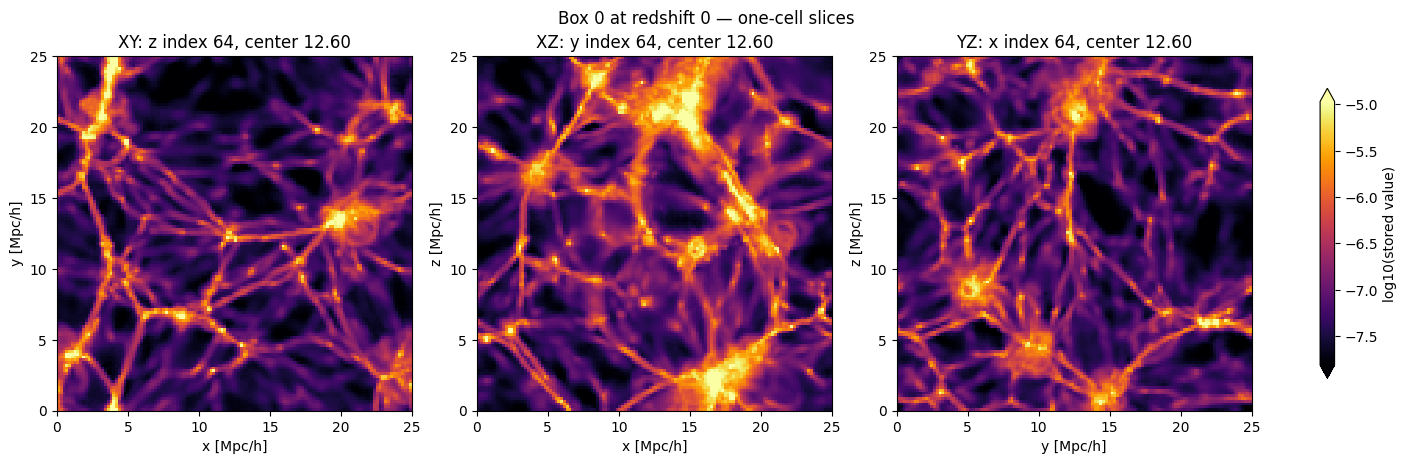

In [25]:
def plot_slices(i=N // 2, j=N // 2, k=N // 2):
    if not all(0 <= index < N for index in (i, j, k)):
        raise ValueError(f'Slice indices must lie between 0 and {N - 1}.')
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True)
    panels = [
        (field[:, :, k].T, 'x', 'y', f'XY: z index {k}, center {centers[k]:.2f}'),
        (field[:, j, :].T, 'x', 'z', f'XZ: y index {j}, center {centers[j]:.2f}'),
        (field[i, :, :].T, 'y', 'z', f'YZ: x index {i}, center {centers[i]:.2f}'),
    ]
    for ax, (image, xlabel, ylabel, title) in zip(axes, panels):
        artist = ax.imshow(np.ma.masked_invalid(image), origin='lower',
                           extent=(0, length, 0, length), cmap=cmap, norm=norm,
                           interpolation='nearest')
        ax.set(title=title, xlabel=f'{xlabel} [{unit}]', ylabel=f'{ylabel} [{unit}]')
    fig.colorbar(artist, ax=axes, label=color_label, shrink=0.8, extend='both')
    fig.suptitle(f'Box {BOX_INDEX} at redshift 0 — one-cell slices')
    return fig

fig = plot_slices()
fig.savefig(OUTPUT_DIR / f'box_{BOX_INDEX}_slices.png', dpi=160)
plt.show()

## 5. 3D structure view

The next view plots cell centers in the upper 1% of the valid values. This exposes spatial structure without hiding everything behind an opaque outer layer. It is a **thresholded point rendering**, not a rendering of every voxel or of individual particles. A reproducible sample limits the point count to 15,000. Change `HIGH_PERCENTILE` to reveal more or less structure; higher values show only the strongest peaks. A static notebook output has a fixed camera; the optional Plotly view below supports rotation.

20,972 cells pass the threshold; showing 15,000.


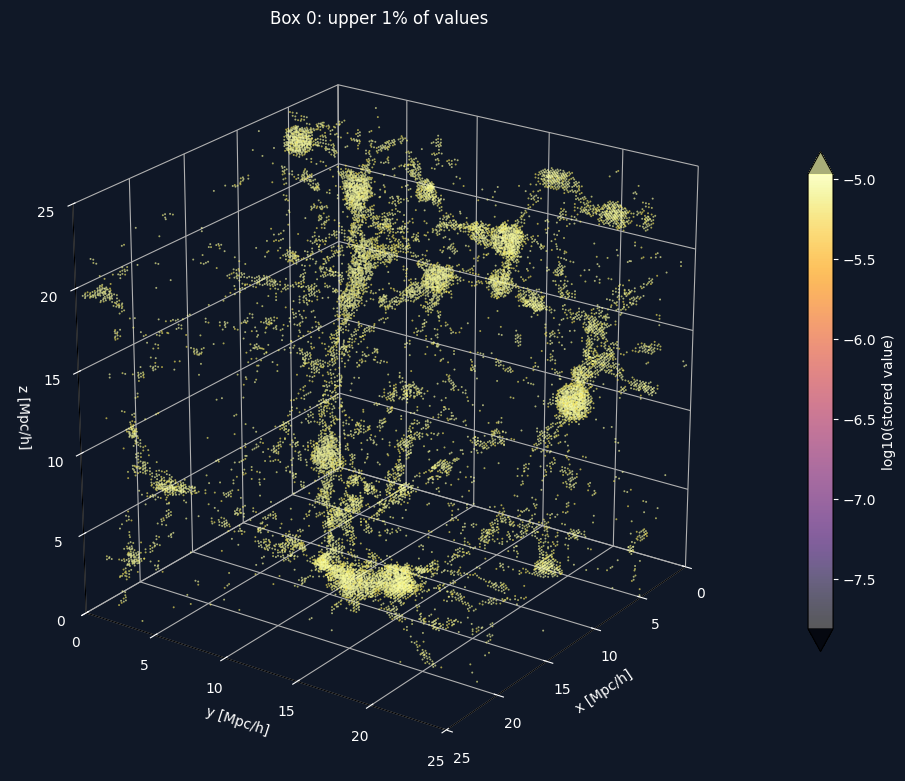

In [26]:
HIGH_PERCENTILE = 99.0
MAX_POINTS = 15_000
if not 0 <= HIGH_PERCENTILE <= 100:
    raise ValueError('HIGH_PERCENTILE must lie between 0 and 100.')
threshold = np.percentile(field[valid], HIGH_PERCENTILE)
indices = np.argwhere(valid & (field >= threshold))
selected_count = len(indices)
if selected_count > MAX_POINTS:
    rng = np.random.default_rng(42)
    indices = indices[rng.choice(selected_count, MAX_POINTS, replace=False)]
coordinates = (indices + 0.5) * spacing
values = field[tuple(indices.T)]

fig = plt.figure(figsize=(9, 8), constrained_layout=True)
ax = fig.add_subplot(111, projection='3d')
# A dark background keeps the bright, high-value cells visible.
fig.patch.set_facecolor('#101827')
ax.set_facecolor('#101827')
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.set_pane_color((0.06, 0.09, 0.15, 1.0))
    axis.label.set_color('white')
ax.tick_params(colors='white')
points = ax.scatter(*coordinates.T, c=values, cmap=cmap, norm=norm,
                    s=2.0, alpha=0.65, linewidths=0, depthshade=False,
                    rasterized=True)
ax.set(xlim=(0, length), ylim=(0, length), zlim=(0, length),
       xlabel=f'x [{unit}]', ylabel=f'y [{unit}]', zlabel=f'z [{unit}]',
       title=f'Box {BOX_INDEX}: upper {100 - HIGH_PERCENTILE:g}% of values')
ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=23, azim=35)
ax.title.set_color('white')
colorbar = fig.colorbar(points, ax=ax, label=color_label, shrink=0.65, pad=0.08, extend='both')
colorbar.ax.tick_params(colors='white')
colorbar.ax.yaxis.label.set_color('white')
fig.savefig(OUTPUT_DIR / f'box_{BOX_INDEX}_3d.png', dpi=170)
print(f'{selected_count:,} cells pass the threshold; showing {len(indices):,}.')
plt.show()

## 6. Several slices along the spatial z axis

Following slices across the box helps distinguish isolated peaks from connected structure. These panels also use the same global color scale.

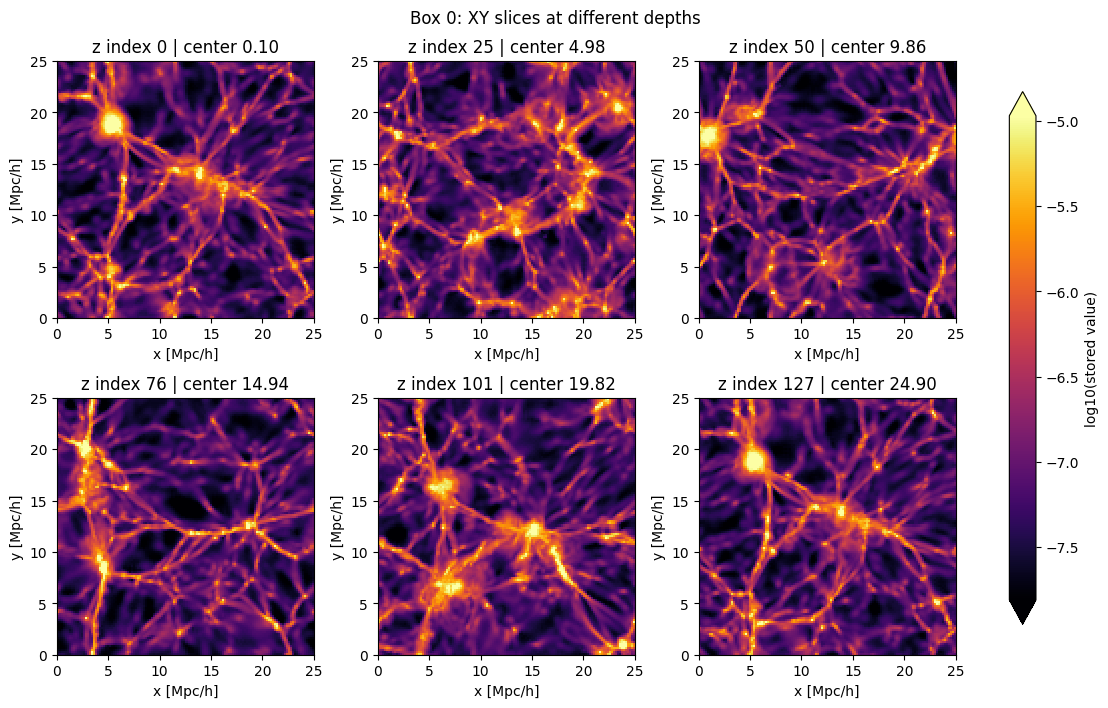

In [6]:
slice_indices = np.linspace(0, N - 1, 6, dtype=int)
fig, axes = plt.subplots(2, 3, figsize=(11, 7), constrained_layout=True)
for ax, k in zip(axes.flat, slice_indices):
    artist = ax.imshow(np.ma.masked_invalid(field[:, :, k].T), origin='lower',
                       extent=(0, length, 0, length), cmap=cmap, norm=norm,
                       interpolation='nearest')
    ax.set(title=f'z index {k} | center {centers[k]:.2f}',
           xlabel=f'x [{unit}]', ylabel=f'y [{unit}]')
fig.colorbar(artist, ax=axes.ravel().tolist(), label=color_label, shrink=0.85, extend='both')
fig.suptitle(f'Box {BOX_INDEX}: XY slices at different depths')
fig.savefig(OUTPUT_DIR / f'box_{BOX_INDEX}_slice_sequence.png', dpi=160)
plt.show()

## 7. Optional interactive slice controls

Requires `ipywidgets` and a notebook frontend that supports widgets. These controls update the three perpendicular slices; they do not change the selected cube. If controls do not appear, edit the indices in `plot_slices(i=64, j=64, k=64)` and rerun the static cell.

In [7]:
try:
    import ipywidgets as widgets
except ImportError:
    print('Optional: install ipywidgets to enable slice sliders.')
else:
    def show_slices(i, j, k):
        plot_slices(i, j, k)
        plt.show()
    slice_controls = widgets.interactive(
        show_slices,
        i=widgets.IntSlider(value=N // 2, min=0, max=N-1, description='x index', continuous_update=True),
        j=widgets.IntSlider(value=N // 2, min=0, max=N-1, description='y index', continuous_update=True),
        k=widgets.IntSlider(value=N // 2, min=0, max=N-1, description='z index', continuous_update=True),
    )
    from IPython.display import display
    display(slice_controls)

interactive(children=(IntSlider(value=64, description='x index', max=127), IntSlider(value=64, description='y …

## 8. Optional interactive 3D volume

Requires `plotly` and WebGL in the notebook frontend. This shows translucent isosurfaces through a coarser 3D volume, using 2×2×2 block **means of the raw values** (128³ → 64³), followed by the same logarithmic transform if enabled. Coarsening improves browser responsiveness but smooths small structures. It is separate from the thresholded full-resolution point view. The 70th–99.5th percentile range of the coarsened valid values controls visible surfaces; opacity controls how much interior structure is visible.

The HTML export includes Plotly itself and can be opened independently. A missing Plotly installation does not prevent any of the Matplotlib figures above.

In [ ]:
try:
    import plotly.graph_objects as go
except ImportError:
    print('Optional: install plotly, then rerun this cell for a rotatable volume.')
else:
    factor = 2
    small_n = N // factor
    # Nonfinite values are excluded from block means.
    raw_for_mean = np.where(np.isfinite(box), box, np.nan)
    coarse = np.nanmean(raw_for_mean.reshape(small_n, factor, small_n, factor, small_n, factor),
                        axis=(1, 3, 5))
    coarse_valid = np.isfinite(coarse) & (coarse > 0) if LOG_SCALE else np.isfinite(coarse)
    coarse_field = np.full(coarse.shape, np.nan, dtype=np.float32)
    if LOG_SCALE:
        np.log10(coarse, out=coarse_field, where=coarse_valid)
    else:
        coarse_field[coarse_valid] = coarse[coarse_valid]
    if not coarse_valid.any():
        raise ValueError('No valid coarse cells.')
    low, high = np.percentile(coarse_field[coarse_valid], [70, 99.5])
    if low == high:
        high = low + max(abs(float(low)) * 1e-6, 1e-6)
    c = (np.arange(small_n) + 0.5) * factor * spacing
    X, Y, Z = np.meshgrid(c, c, c, indexing='ij')
    volume = go.Figure(go.Volume(
        x=X.ravel(), y=Y.ravel(), z=Z.ravel(), value=coarse_field.ravel(),
        isomin=float(low), isomax=float(high), opacity=0.07, surface_count=16,
        colorscale='Inferno', cmin=float(vmin), cmax=float(vmax),
        colorbar=dict(title=color_label), caps=dict(x_show=False, y_show=False, z_show=False),
    ))
    volume.update_layout(
        title=f'Box {BOX_INDEX}: coarsened 3D volume (drag to rotate)',
        scene=dict(aspectmode='cube',
                   xaxis=dict(title=f'x [{unit}]', range=[0, length]),
                   yaxis=dict(title=f'y [{unit}]', range=[0, length]),
                   zaxis=dict(title=f'z [{unit}]', range=[0, length])),
        height=700,
    )
    html_path = OUTPUT_DIR / f'box_{BOX_INDEX}_interactive_volume.html'
    volume.write_html(html_path, include_plotlyjs=True)
    print('Saved:', html_path)
    volume.show()

## Next experiments

- Change `BOX_INDEX` to inspect another of the 27 cubes, then rerun from section 3.
- Switch the filename to `CMD-3D-CV-128-1.5.npy` to inspect the other available redshift. Confirm simulation ordering before interpreting differences between corresponding cube indices.
- A slice fixes one coordinate. A projection combines values along an axis: for example, `box.mean(axis=2)` averages through spatial z and differs from `box[:, :, 64]`. If using a logarithmic projection display, average raw values first and then take the logarithm.
- Confirm the field name, units, simulation suite, and box length from the original download before making physical claims. The visualizations label the stored scalar generically for that reason.